In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, mannwhitneyu, pearsonr, spearmanr
import os
# ...existing code...
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
)
from pathlib import Path

In [54]:
data_path = "/home/jake/Documents/AI_Clinician/experiments"
df_file = "combined_hourly_features_phoenix_sepsis_prop_0.8.parquet"
df = pd.read_parquet(os.path.join(data_path, df_file))
df

,encounter_id,time,airway_type,breath_sequence,control_variable,expiratory_pressure,fio2,mean_airway_pressure,mode_of_ventilation,nitric_oxide,...,vis,age,mortality,sex,white,black,hispanic,asian,other,health_score
0,1165293630,2239-06-12 00:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,0.0,0.00,0.0,1.0,0,0,0,1,0,1.035526
1,1165293630,2239-06-12 01:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,0.0,0.00,0.0,1.0,0,0,0,1,0,1.034166
2,1165293630,2239-06-12 02:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,0.0,0.00,0.0,1.0,0,0,0,1,0,1.037823
3,1165293630,2239-06-12 03:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,0.0,0.00,0.0,1.0,0,0,0,1,0,1.038765
4,1165293630,2239-06-12 04:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,0.0,0.00,0.0,1.0,0,0,0,1,0,1.037153
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2878185,1189429156,2254-11-02 19:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,0.0,232.44,0.0,1.0,1,0,0,0,0,1.374050
2878186,1189429156,2254-11-02 20:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,0.0,232.44,0.0,1.0,1,0,0,0,0,1.382135
2878187,1189429156,2254-11-02 21:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,0.0,232.44,0.0,1.0,1,0,0,0,0,1.375656
2878188,1189429156,2254-11-02 22:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,0.0,232.44,0.0,1.0,1,0,0,0,0,1.375656


In [65]:
    encounter_ids = df['encounter_id'].unique()
    mortality_ids = df[df['mortality'] == 1]['encounter_id'].unique()
    # survival_ids are encounter_ids not in mortality_ids
    survival_ids = np.array([eid for eid in encounter_ids if eid not in mortality_ids])

    survival_df = df[df['encounter_id'].isin(survival_ids)]
    mortality_df = df[df['encounter_id'].isin(mortality_ids)]
    mortality_df.loc[:, 'mortality'] = 1


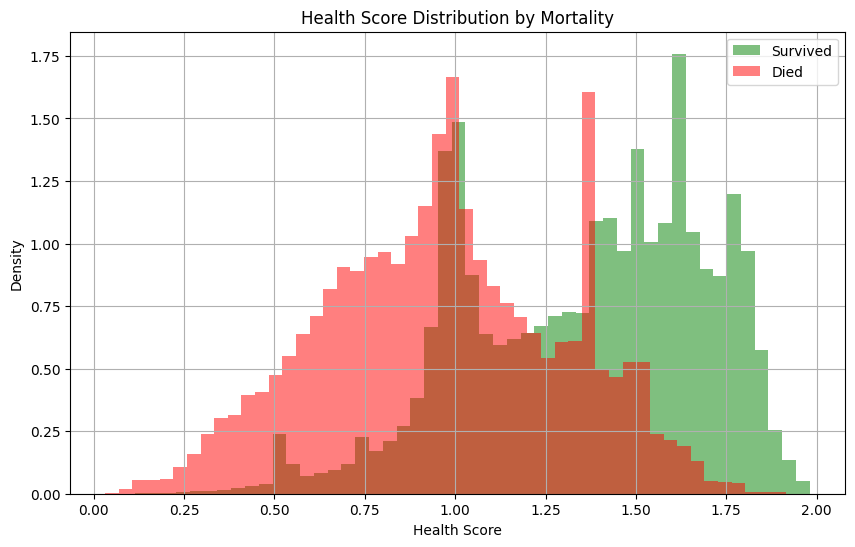

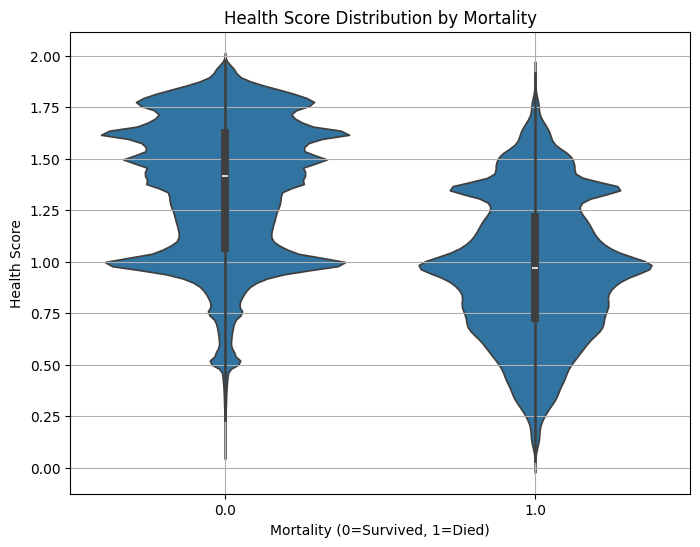

In [67]:
    plt.figure(figsize=(10,6))
    plt.hist(survival_df['health_score'], bins=50, alpha=0.5, label='Survived', color='g', density=True)
    plt.hist(mortality_df['health_score'], bins=50, alpha=0.5, label='Died', color='r', density=True)
    plt.xlabel('Health Score')
    plt.ylabel('Density')
    plt.title('Health Score Distribution by Mortality')
    plt.legend()
    plt.grid(True)
    plt.show()


    # plot as violin plot
    plt.figure(figsize=(8,6))
    sns.violinplot(x='mortality', y='health_score', data=pd.concat([survival_df, mortality_df]))
    plt.xlabel('Mortality (0=Survived, 1=Died)')
    plt.ylabel('Health Score')
    plt.title('Health Score Distribution by Mortality')
    plt.grid(True)
    plt.show()


In [68]:

    # calculate the statistical difference between the two groups
    t_stat, t_p = ttest_ind(survival_df['health_score'], mortality_df['health_score'], equal_var=False)
    mw_stat, mw_p = mannwhitneyu(survival_df['health_score'], mortality_df['health_score'], alternative='two-sided')
    print(f"T-test: stat={t_stat:.3f}, p={t_p:.3e}")
    print(f"Mann-Whitney U test: stat={mw_stat:.3f}, p={mw_p:.3e}")

T-test: stat=523.163, p=0.000e+00
Mann-Whitney U test: stat=454894497198.000, p=0.000e+00


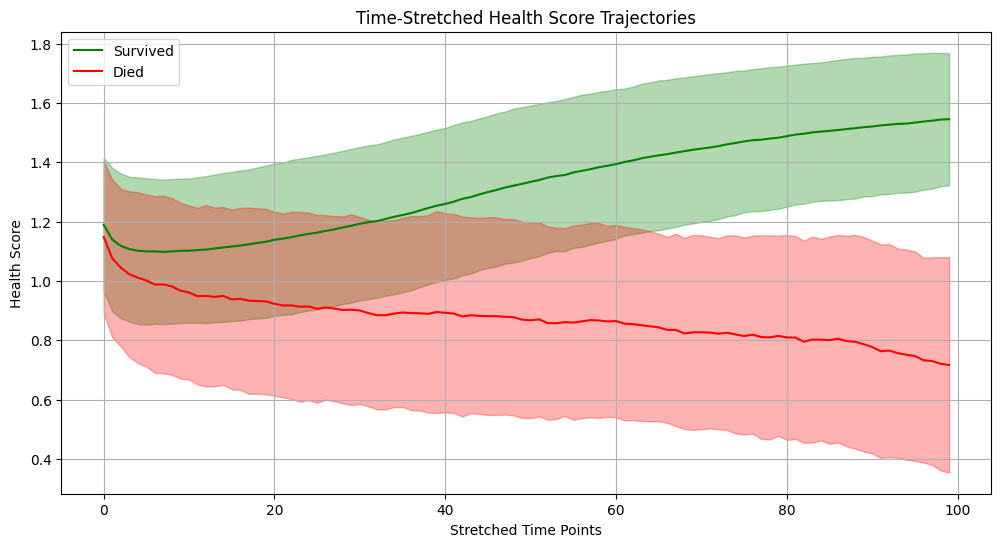

In [69]:
def stretch_trajectory(df, num_points=100):
    stretched = []
    for eid in df['encounter_id'].unique():
        traj = df[df['encounter_id'] == eid].sort_values('time')['health_score'].values
        if len(traj) < 2:
            continue
        stretched_traj = np.interp(np.linspace(0, len(traj)-1, num_points), np.arange(len(traj)), traj)
        stretched.append(stretched_traj)
    return np.array(stretched)

survival_stretched = stretch_trajectory(survival_df)
mortality_stretched = stretch_trajectory(mortality_df)

# plot mean and std dev
plt.figure(figsize=(12,6))
plt.plot(np.mean(survival_stretched, axis=0), label='Survived', color='g')
plt.fill_between(np.arange(survival_stretched.shape[1]), 
                    np.mean(survival_stretched, axis=0) - np.std(survival_stretched, axis=0),
                    np.mean(survival_stretched, axis=0) + np.std(survival_stretched, axis=0),
                    color='g', alpha=0.3)
plt.plot(np.mean(mortality_stretched, axis=0), label='Died', color='r')
plt.fill_between(np.arange(mortality_stretched.shape[1]), 
                    np.mean(mortality_stretched, axis=0) - np.std(mortality_stretched, axis=0),
                    np.mean(mortality_stretched, axis=0) + np.std(mortality_stretched, axis=0),
                    color='r', alpha=0.3)
plt.xlabel('Stretched Time Points')
plt.ylabel('Health Score')
plt.title('Time-Stretched Health Score Trajectories')
plt.legend()
plt.grid(True)
plt.show()


In [96]:
df.loc[df['encounter_id'].isin(mortality_ids), 'mortality'] = 1

def compute_and_plot_auc(
    dataframe,
    score_col="health_score_for_auc",
    outcome_col="mortality",
    out_dir=".",
    plot_name = None,
    n_boot=100,
    random_state=42,
    output_dir = None
):
    """
    Compute ROC AUC and Average Precision (PR AUC), plot ROC and PR curves,
    and return metrics with bootstrap CIs (percentile).
    Uses causal ordering of dataframes assumed pre-aggregated per-row (not per-encounter).
    For per-encounter evaluation, aggregate scores first (e.g. sum or last score).
    """

    # get arrays (ensure binary 0/1)
    y_true = dataframe[outcome_col].astype(int).values
    y_score = dataframe[score_col].astype(float).values

    # primary metrics
    try:
        roc_auc = float(roc_auc_score(y_true, y_score))
    except ValueError:
        roc_auc = float("nan")
    try:
        ap = float(average_precision_score(y_true, y_score))
    except ValueError:
        ap = float("nan")

    # ROC curve
    fpr, tpr, roc_thresh = roc_curve(y_true, y_score)
    # PR curve
    prec, rec, pr_thresh = precision_recall_curve(y_true, y_score)

    # bootstrap CI for roc_auc
    rng = np.random.RandomState(random_state)
    boot_aucs = []
    boot_aps = []
    n = len(y_true)
    for i in range(n_boot):
        idx = rng.randint(0, n, n)  # sample with replacement
        y_t = y_true[idx]
        y_s = y_score[idx]
        # require both classes in sample
        if y_t.sum() == 0 or y_t.sum() == len(y_t):
            continue
        try:
            boot_aucs.append(roc_auc_score(y_t, y_s))
            boot_aps.append(average_precision_score(y_t, y_s))
        except Exception:
            continue

    def ci(arr, alpha=0.05):
        if len(arr) == 0:
            return (np.nan, np.nan)
        lo = np.percentile(arr, 100 * (alpha / 2.0))
        hi = np.percentile(arr, 100 * (1.0 - alpha / 2.0))
        return float(lo), float(hi)

    roc_ci = ci(boot_aucs)
    ap_ci = ci(boot_aps)

    # Plot ROC and PR side-by-side
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    # ROC
    ax = axes[0]
    ax.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f} (CI {roc_ci[0]:.3f}-{roc_ci[1]:.3f})", color="C0")
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title("ROC curve")
    ax.legend(loc="lower right")
    ax.grid(True)

    # PR
    ax = axes[1]
    ax.plot(rec, prec, label=f"AP = {ap:.3f} (CI {ap_ci[0]:.3f}-{ap_ci[1]:.3f})", color="C1")
    # baseline precision = positive prevalence
    pos_rate = max(y_true.mean(), 1e-12)
    ax.hlines(pos_rate, 0, 1, linestyle="--", color="gray", label=f"baseline={pos_rate:.3f}")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_title("Precision-Recall curve (good for imbalanced data)")
    ax.legend(loc="lower left")
    ax.grid(True)

    plt.tight_layout()
    out_path = os.path.join(out_dir, f"{plot_name} roc_pr_curves.png")
    fig.savefig(out_path, dpi=200)
    plt.show()
    
    # return summary
    summary = {
        "roc_auc": roc_auc,
        "roc_auc_ci": roc_ci,
        "average_precision": ap,
        "average_precision_ci": ap_ci,
        "pos_rate": float(pos_rate),
        "n_samples": int(n),
        "n_boot_valid": len(boot_aucs),
        "plot": str(out_path),
    }

    # save summary to txt
    with open(os.path.join(output_dir, "health_score_auc_summary.txt"), "w") as f:
        for k, v in summary.items():
            f.write(f"{k}: {v}\n")

        print("Health score AUC and AP summary saved to", output_dir)
    
    
    return summary




In [97]:
df['health_score_for_auc'] = 1 - df['health_score'] / 2.0

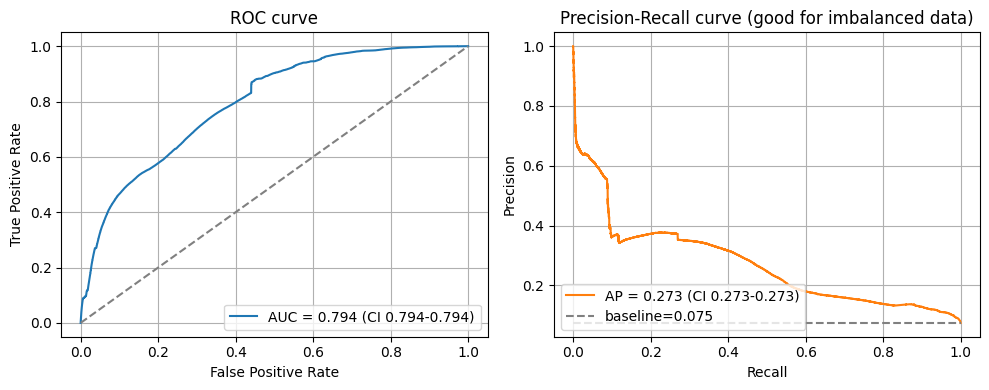

Health score AUC and AP summary saved to /home/jake/Documents/AI_Clinician/experiments/reward_analysis


{'roc_auc': 0.7941881564097677,
 'roc_auc_ci': (0.794164173280204, 0.794164173280204),
 'average_precision': 0.2728749601146101,
 'average_precision_ci': (0.27261636714580034, 0.27261636714580034),
 'pos_rate': 0.0747271722853599,
 'n_samples': 2878190,
 'n_boot_valid': 1,
 'plot': './health_score_auc_pr_curve.png roc_pr_curves.png'}

In [98]:
compute_and_plot_auc(
    df.copy(), 
    score_col="health_score_for_auc",
    outcome_col="mortality",
    out_dir=".",
    plot_name = "health_score_auc_pr_curve.png",
    n_boot=1,
    random_state=42,
    output_dir = "/home/jake/Documents/AI_Clinician/experiments/reward_analysis"
    )

In [99]:
# compute difference in health_score 
df['health_score_diff'] = df.groupby('encounter_id')['health_score'].diff()

# shift the health_score_diff back one time point across the entire dataframe
df['health_score_diff'] = df['health_score_diff'].shift(-1).fillna(0)

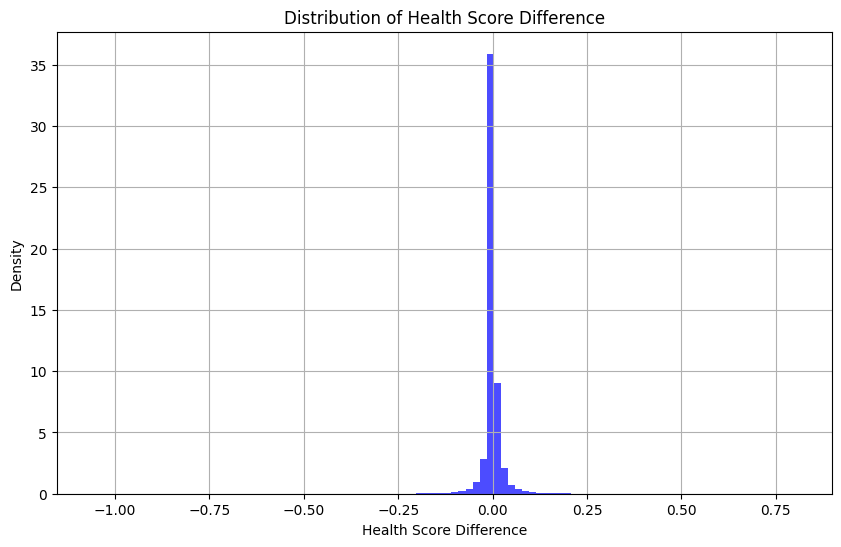

In [100]:
# plot the distribution of health_score_diff 
plt.figure(figsize=(10,6))
plt.hist(df['health_score_diff'], bins=100, alpha=0.7, color='b', density=True)
plt.xlabel('Health Score Difference')
plt.ylabel('Density')
plt.title('Distribution of Health Score Difference')
plt.grid(True)
plt.show()

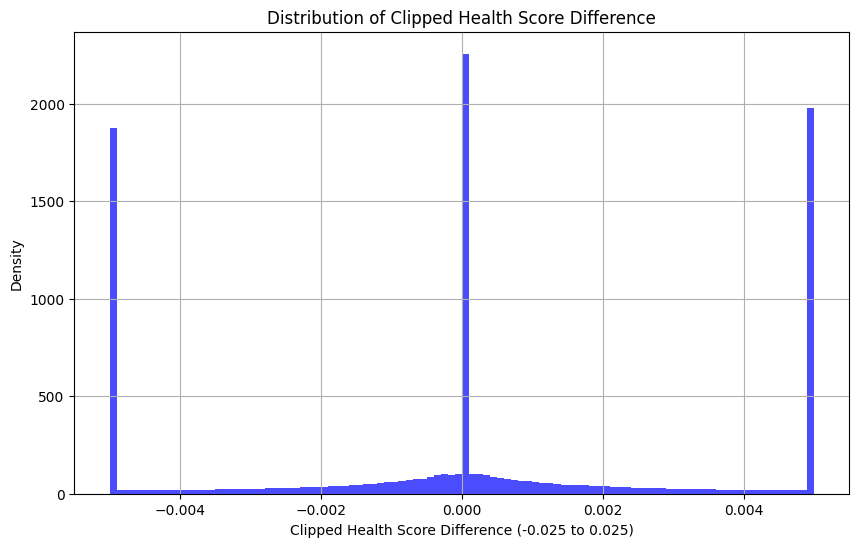

In [101]:
# clip to -.025 to .025
df['health_score_diff'] = df['health_score_diff'].clip(-0.005, 0.005)
# replot distribution
plt.figure(figsize=(10,6))
plt.hist(df['health_score_diff'], bins=100, alpha=0.7, color='b', density=True)
plt.xlabel('Clipped Health Score Difference (-0.025 to 0.025)')
plt.ylabel('Density')
plt.title('Distribution of Clipped Health Score Difference')
plt.grid(True)
plt.show()  

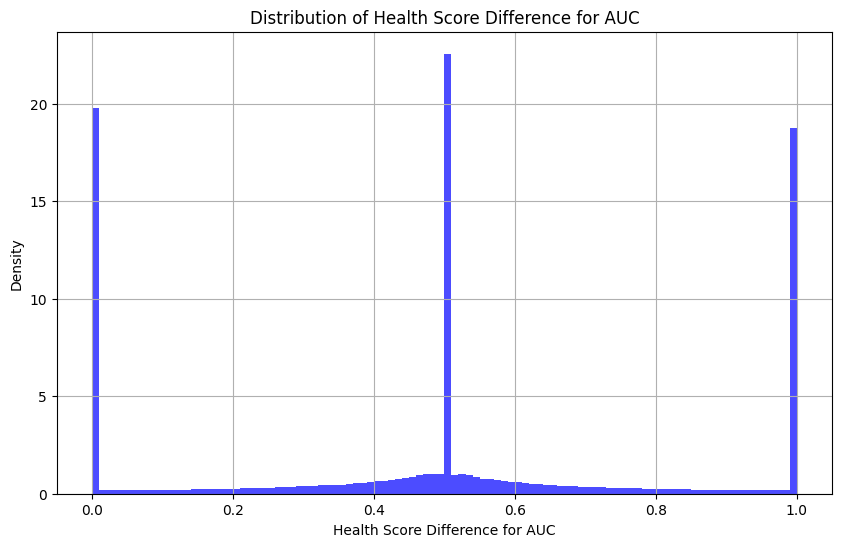

In [102]:
# for auroc computation, create a new column where higher health_score_diff means worse outcome
df['health_score_diff_for_auc'] = (-df['health_score_diff'] + 0.005)/0.01

# plot the distribution of health_score_diff_for_auc
plt.figure(figsize=(10,6))
plt.hist(df['health_score_diff_for_auc'], bins=100, alpha=0.7, color='b', density=True)
plt.xlabel('Health Score Difference for AUC')
plt.ylabel('Density')
plt.title('Distribution of Health Score Difference for AUC')
plt.grid(True)
plt.show()

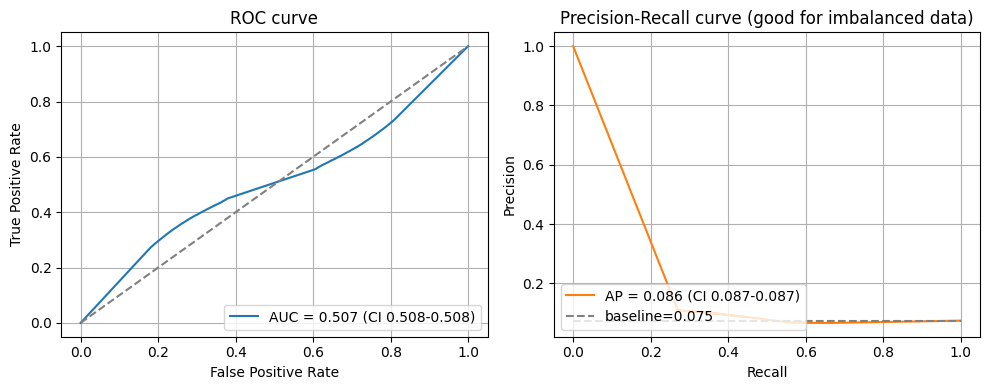

Health score AUC and AP summary saved to /home/jake/Documents/AI_Clinician/experiments/reward_analysis


{'roc_auc': 0.5067722392768107,
 'roc_auc_ci': (0.5078584393830816, 0.5078584393830816),
 'average_precision': 0.08643158530793243,
 'average_precision_ci': (0.08684053590821661, 0.08684053590821661),
 'pos_rate': 0.0747271722853599,
 'n_samples': 2878190,
 'n_boot_valid': 1,
 'plot': './health_score_diff_auc_pr_curve.png roc_pr_curves.png'}

In [103]:
compute_and_plot_auc(
    df.copy(), 
    score_col="health_score_diff_for_auc",
    outcome_col="mortality",
    plot_name = "health_score_diff_auc_pr_curve.png",
    out_dir=".",
    n_boot=1,
    random_state=42,
    output_dir = "/home/jake/Documents/AI_Clinician/experiments/reward_analysis"
    )

# health score diff doesn't seem to track mortality. 
## We will try smoothing it

In [72]:
compute_health_score_outcome_correlation(df.copy(), "/home/jake/Documents/AI_Clinician/experiments/reward_analysis")

Health score AUC and AP summary saved to /home/jake/Documents/AI_Clinician/experiments/reward_analysis


In [36]:
output_dir

NameError: name 'output_dir' is not defined

In [16]:
df = df[['encounter_id', 'time', 'mortality', 'health_score']].copy()
    
# create health_score_diff as the difference in health score from previous time point
df['health_score_diff'] = df['health_score'].diff()

# shift the health_score_diff back one time point across the entire dataframe
df['health_score_diff'] = df['health_score_diff'].shift(-1).fillna(0)

encounter_ids = df['encounter_id'].unique()
mortality_ids = df[df['mortality'] == 1]['encounter_id'].unique()
df.loc[df['encounter_id'].isin(mortality_ids), 'mortality'] = 1 # make all mortality 1 at all timesteps for non-survivors


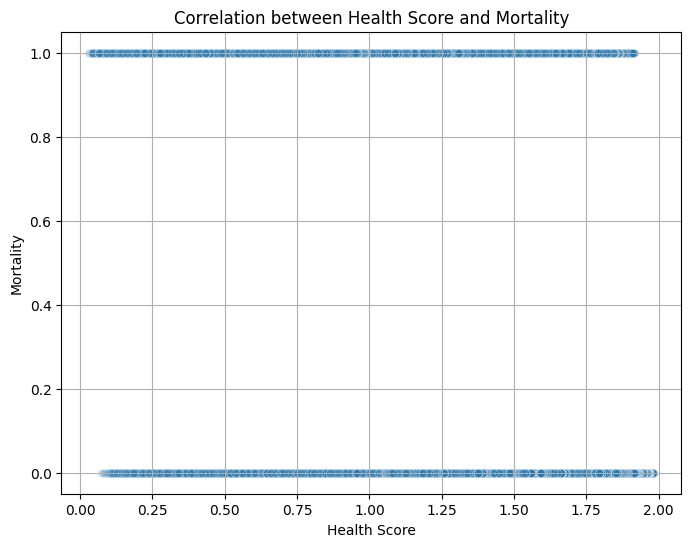

Pearson correlation between health score and mortality: r=-0.296, p=0.000e+00
Spearman correlation between health score and mortality: r=-0.268, p=0.000e+00


In [19]:
# plot correlation between health score and mortality
mortality = df['mortality'].values
health_score = df['health_score'].values

plt.figure(figsize=(8,6))
sns.scatterplot(x=health_score, y=mortality, alpha=0.3)
plt.xlabel('Health Score')
plt.ylabel('Mortality')
plt.title('Correlation between Health Score and Mortality')
plt.grid()
plt.show()

# compute pearson correlation between health score and mortality
pearson_corr, pearson_p = pearsonr(health_score, mortality)
spearman_corr, spearman_p = spearmanr(health_score, mortality)
print(f"Pearson correlation between health score and mortality: r={pearson_corr:.3f}, p={pearson_p:.3e}")
print(f"Spearman correlation between health score and mortality: r={spearman_corr:.3f}, p={spearman_p:.3e}")

In [ ]:
# plot correlation between health score and mortality



In [17]:
df['health_score'].diff()

0               NaN
1         -0.001360
2          0.003657
3          0.000942
4         -0.001612
             ...   
2878185    0.004489
2878186    0.008085
2878187   -0.006478
2878188    0.000000
2878189   -0.000559
Name: health_score, Length: 2878190, dtype: float64

0          1.035526
1          1.034166
2          1.037823
3          1.038765
4          1.037153
             ...   
2878185    1.374050
2878186    1.382135
2878187    1.375656
2878188    1.375656
2878189    1.375098
Name: health_score, Length: 2878190, dtype: float64